# Network-constrained electricity market clearing with losses and investment

This notebook extends the fixed-network social-surplus-maximizing model with a uniform transmission loss on every edge and a greedy transmission-expansion search for the bidding areas in `data/`.

For a selected 15-minute delivery period, cumulative supply and demand schedules are converted into incremental bid blocks. The optimizer chooses accepted supply, accepted demand, and directional inter-area flows to maximize gross willingness to pay minus supply offer cost.

A transfer sent on an edge delivers `(1 - EDGE_LOSS_FRACTION)` times its sent quantity to the receiving market. The greedy outer loop tests candidate new links and adds the best welfare-improving link that fits within the remaining budget.

This remains a transport model: it does not include AC/DC grid physics, unit commitment, reserves, or strategic bidding. Capacities, loss rate, coordinates, and investment costs are illustrative assumptions, not verified historical data.

## 1. Imports and user configuration

Change `PERIOD_INDEX` to select one of the 96 quarter-hours. Run this notebook with the repository root as the working directory so that `./data` is found.

The starting capacities are illustrative. The candidate-link capacity is calculated as the median of the starting capacities after the configured capacity scale. Loss rate, candidate capacity, cost coefficient, and expansion budget are explicit editable assumptions.

In [18]:
from pathlib import Path
import json
import math

import gurobipy as gp
from gurobipy import GRB
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

# Run from the repository root; the market data are in ./data.
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
PERIOD_INDEX = 0
PLOT_MARKET = "AT"

if not DATA_DIR.exists():
    raise FileNotFoundError(
        "Could not find ./data. Start Jupyter in the repository root, "
        "or set PROJECT_DIR above to that folder."
    )

print(f"Project directory: {PROJECT_DIR}")
print(f"Gurobi version: {gp.gurobi.version()}")

Project directory: /Users/gsims/Documents/GitHub/d2a_project
Gurobi version: (12, 0, 3)


## 2. Load and validate the market files

In [19]:
def load_market_files(data_dir):
    """Load one JSON-formatted .txt file per aggregate bidding area."""
    markets = {}
    source_paths = {}

    for path in sorted(Path(data_dir).glob("*.txt")):
        with path.open("r", encoding="utf-8") as handle:
            payload = json.load(handle)

        area = payload.get("aggregatedBiddingArea")
        periods = payload.get("aggregatedPoints", [])
        if not area or not periods:
            raise ValueError(f"{path.name} is missing its area code or delivery periods")
        if area in markets:
            raise ValueError(f"Duplicate aggregate bidding area: {area}")

        markets[area] = payload
        source_paths[area] = path

    if not markets:
        raise FileNotFoundError(f"No .txt market files found in {data_dir}")

    period_counts = {area: len(payload["aggregatedPoints"]) for area, payload in markets.items()}
    if len(set(period_counts.values())) != 1:
        raise ValueError(f"Market files have inconsistent period counts: {period_counts}")

    return markets, source_paths


markets, source_paths = load_market_files(DATA_DIR)

market_overview = pd.DataFrame(
    [
        {
            "market": area,
            "periods": len(payload["aggregatedPoints"]),
            "delivery_date": payload.get("deliveryDate"),
            "file": source_paths[area].name,
        }
        for area, payload in sorted(markets.items())
    ]
)

print(f"Loaded {len(markets)} markets.")
display(market_overview)

Loaded 13 markets.


,market,periods,delivery_date,file
0,AT,96,2026-09-08,at.txt
1,BALTIC,96,2026-09-08,baltic.txt
2,BE,96,2026-09-08,be.txt
3,BG,96,2026-09-08,bg.txt
4,DE-LU,96,2026-09-08,de_lu.txt
5,DK,96,2026-09-08,dk.txt
6,FI,96,2026-09-08,fi.txt
7,FR,96,2026-09-08,fr.txt
8,NL,96,2026-09-08,nl.txt
9,NO,96,2026-09-08,no.txt


## 3. Convert cumulative schedules into incremental blocks

The raw curves are cumulative. Whenever cumulative quantity rises, the increase becomes one bounded bid block. A vertical price move with no quantity change creates no block. Adjacent blocks at the same price are merged.

The first cumulative quantity is treated as a block measured from zero. This preserves the absolute submitted supply and demand schedules rather than re-centering each market around its observed clearing point.

In [20]:
def cumulative_curve_to_blocks(series_data, side, quantity_tolerance=1e-7, price_tolerance=1e-10):
    """Convert one cumulative supply or demand schedule to (price, quantity) blocks."""
    if side not in {"supply", "demand"}:
        raise ValueError("side must be 'supply' or 'demand'")

    price_key = f"{side}Price"
    quantity_key = f"{side}Quantity"
    points = [
        (float(row[price_key]), float(row[quantity_key]))
        for row in series_data
        if price_key in row and quantity_key in row
    ]
    if not points:
        raise ValueError(f"No complete {side} price-quantity points found")

    blocks = []
    previous_quantity = 0.0
    for price, cumulative_quantity in points:
        if not (math.isfinite(price) and math.isfinite(cumulative_quantity)):
            raise ValueError(f"Non-finite {side} point: {(price, cumulative_quantity)}")
        if cumulative_quantity < previous_quantity - quantity_tolerance:
            raise ValueError(
                f"{side.title()} cumulative quantity fell from "
                f"{previous_quantity} to {cumulative_quantity}"
            )

        block_quantity = cumulative_quantity - previous_quantity
        if block_quantity > quantity_tolerance:
            if blocks and abs(blocks[-1]["price"] - price) <= price_tolerance:
                blocks[-1]["quantity"] += block_quantity
            else:
                blocks.append({"price": price, "quantity": block_quantity})
        previous_quantity = max(previous_quantity, cumulative_quantity)

    result = pd.DataFrame(blocks)
    result.insert(0, "block_id", np.arange(len(result), dtype=int))
    result["side"] = side
    return result[["block_id", "side", "price", "quantity"]]


def published_price_summary(period):
    """Return published component prices and their mean for an aggregate file."""
    records = period.get("priceAreas", [])
    prices = {
        str(record["area"]): float(record["price"])
        for record in records
        if "area" in record and "price" in record
    }
    mean_price = float(np.mean(list(prices.values()))) if prices else np.nan
    return prices, mean_price


def prepare_period(markets, period_index):
    """Parse the selected period for every market into optimizer-ready blocks."""
    prepared = {}
    delivery_starts = set()
    delivery_ends = set()

    for area, payload in sorted(markets.items()):
        periods = payload["aggregatedPoints"]
        if period_index < 0 or period_index >= len(periods):
            raise IndexError(f"PERIOD_INDEX={period_index} is invalid for {area}")

        period = periods[period_index]
        delivery_starts.add(period["deliveryStart"])
        delivery_ends.add(period["deliveryEnd"])
        prices, mean_price = published_price_summary(period)
        prepared[area] = {
            "supply": cumulative_curve_to_blocks(period["seriesData"], "supply"),
            "demand": cumulative_curve_to_blocks(period["seriesData"], "demand"),
            "published_prices": prices,
            "published_price_mean": mean_price,
            "delivery_start": period["deliveryStart"],
            "delivery_end": period["deliveryEnd"],
        }

    if len(delivery_starts) != 1 or len(delivery_ends) != 1:
        raise ValueError(
            "The selected period is not time-aligned across markets: "
            f"starts={delivery_starts}, ends={delivery_ends}"
        )

    return prepared


period_data = prepare_period(markets, PERIOD_INDEX)
delivery_start = next(iter(period_data.values()))["delivery_start"]
delivery_end = next(iter(period_data.values()))["delivery_end"]

block_summary = pd.DataFrame(
    [
        {
            "market": area,
            "supply_blocks": len(data["supply"]),
            "max_supply_mw": data["supply"]["quantity"].sum(),
            "demand_blocks": len(data["demand"]),
            "max_demand_mw": data["demand"]["quantity"].sum(),
            "published_price_mean": data["published_price_mean"],
        }
        for area, data in sorted(period_data.items())
    ]
)

print(f"Selected period {PERIOD_INDEX}: {delivery_start} to {delivery_end}")
display(block_summary)

Selected period 0: 2026-09-07T22:00:00Z to 2026-09-07T22:15:00Z


,market,supply_blocks,max_supply_mw,demand_blocks,max_demand_mw,published_price_mean
0,AT,26,"3,465.700",42,"3,571.400",224.970
1,BALTIC,225,"3,178.900",268,"2,582.700",5.000
2,BE,128,"4,512.900",135,"5,851.700",206.480
3,BG,92,"2,890.300",706,"2,919.300",224.550
4,DE-LU,353,"33,960.500",604,"40,817.300",205.990
5,DK,245,"4,794.400",178,"5,882.700",206.100
6,FI,289,"9,427.000",213,"8,972.900",2.030
7,FR,102,"19,334.100",83,"19,826.100",207.650
8,NL,381,"9,579.700",328,"11,940.200",206.000
9,NO,785,"18,993.500",175,"13,548.852",105.924


### Inspect one transformed market

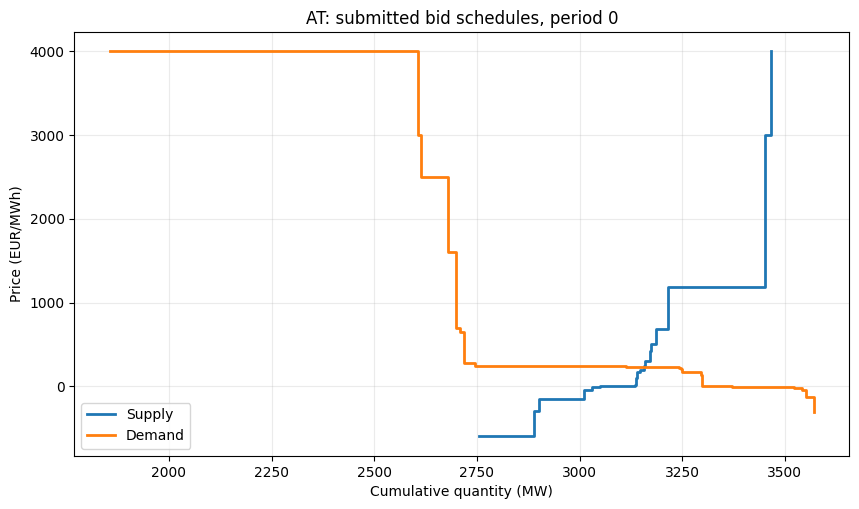

First 10 incremental supply blocks


,block_id,side,price,quantity,cumulative_quantity
0,0,supply,-600.000,"2,756.400","2,756.400"
1,1,supply,-599.900,29.500,"2,785.900"
2,2,supply,-301.000,103.296,"2,889.196"
3,3,supply,-300.000,8.204,"2,897.400"
4,4,supply,-150.000,5.000,"2,902.400"
5,5,supply,-131.600,109.000,"3,011.400"
6,6,supply,-50.000,0.500,"3,011.900"
7,7,supply,-5.000,18.100,"3,030.000"
8,8,supply,-1.000,20.100,"3,050.100"
9,9,supply,0.000,42.500,"3,092.600"


First 10 incremental demand blocks


,block_id,side,price,quantity,cumulative_quantity
0,0,demand,"4,000.000","1,855.800","1,855.800"
1,1,demand,"3,999.900",606.800,"2,462.600"
2,2,demand,"3,000.000",144.233,"2,606.833"
3,3,demand,"2,500.010",7.867,"2,614.700"
4,4,demand,"2,500.000",15.800,"2,630.500"
5,5,demand,"1,606.000",50.000,"2,680.500"
6,6,demand,699.990,19.600,"2,700.100"
7,7,demand,688.900,7.800,"2,707.900"
8,8,demand,650.000,0.300,"2,708.200"
9,9,demand,520.000,10.000,"2,718.200"


In [21]:
if PLOT_MARKET not in period_data:
    raise KeyError(f"PLOT_MARKET={PLOT_MARKET!r} is not one of {sorted(period_data)}")

supply_plot = period_data[PLOT_MARKET]["supply"].copy()
demand_plot = period_data[PLOT_MARKET]["demand"].copy()
supply_plot["cumulative_quantity"] = supply_plot["quantity"].cumsum()
demand_plot["cumulative_quantity"] = demand_plot["quantity"].cumsum()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.step(
    supply_plot["cumulative_quantity"], supply_plot["price"],
    where="post", label="Supply", linewidth=2,
)
ax.step(
    demand_plot["cumulative_quantity"], demand_plot["price"],
    where="post", label="Demand", linewidth=2,
)
ax.set_title(f"{PLOT_MARKET}: submitted bid schedules, period {PERIOD_INDEX}")
ax.set_xlabel("Cumulative quantity (MW)")
ax.set_ylabel("Price (EUR/MWh)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

print("First 10 incremental supply blocks")
display(supply_plot.head(10))
print("First 10 incremental demand blocks")
display(demand_plot.head(10))

## 4. Define the starting transport network

Each row is one undirected commercial interconnector. The solver represents both possible directions with separate nonnegative flow variables and a binary direction choice, so a link cannot carry simultaneous counterflows. The receiving market gets `(1 - EDGE_LOSS_FRACTION)` times the sent quantity.

The capacities below are illustrative, not a verified historical dataset. Newly considered links use the median of these capacities after applying the demonstration scale. Replace the example with sourced, date-consistent capacities before interpreting results empirically.

In [22]:
BASE_INTERCONNECTORS = pd.DataFrame(
    [
        # Central-western Europe
        ("AT", "DE-LU", 4_000.0),
        ("BE", "DE-LU", 2_000.0),
        ("BE", "FR", 3_500.0),
        ("BE", "NL", 2_400.0),
        ("DE-LU", "FR", 4_000.0),
        ("DE-LU", "NL", 5_000.0),
        ("DE-LU", "PL", 2_500.0),
        # Nordic and continental links
        ("DE-LU", "DK", 2_500.0),
        ("DE-LU", "SE", 600.0),
        ("DK", "NL", 700.0),
        ("DK", "NO", 1_700.0),
        ("DK", "SE", 2_000.0),
        ("FI", "NO", 100.0),
        ("FI", "SE", 2_700.0),
        ("NO", "NL", 700.0),
        ("NO", "SE", 3_500.0),
        # Baltic and eastern links
        ("BALTIC", "FI", 1_000.0),
        ("BALTIC", "PL", 500.0),
        ("BALTIC", "SE", 700.0),
        ("PL", "SE", 600.0),
        ("BG", "RO", 1_500.0),
    ],
    columns=["from_market", "to_market", "capacity_mw"],
)

# A conservative demonstration scale that makes transfer scarcity visible.
# Set this to 1.0 to use the round base values exactly as listed above.
ILLUSTRATIVE_CAPACITY_SCALE = 0.5
INTERCONNECTORS = BASE_INTERCONNECTORS.copy()
INTERCONNECTORS["capacity_mw"] *= ILLUSTRATIVE_CAPACITY_SCALE


def validate_interconnectors(interconnectors, valid_markets):
    required = {"from_market", "to_market", "capacity_mw"}
    if not required.issubset(interconnectors.columns):
        raise ValueError(f"Interconnector table must contain {sorted(required)}")

    unknown = (
        set(interconnectors["from_market"])
        | set(interconnectors["to_market"])
    ) - set(valid_markets)
    if unknown:
        raise ValueError(f"Unknown markets in interconnector table: {sorted(unknown)}")
    if (interconnectors["from_market"] == interconnectors["to_market"]).any():
        raise ValueError("Self-links are not allowed")
    if (interconnectors["capacity_mw"] < 0).any():
        raise ValueError("Capacities must be nonnegative")

    normalized_pairs = interconnectors.apply(
        lambda row: tuple(sorted((row["from_market"], row["to_market"]))), axis=1
    )
    if normalized_pairs.duplicated().any():
        duplicates = normalized_pairs[normalized_pairs.duplicated(keep=False)].tolist()
        raise ValueError(f"Duplicate undirected links: {duplicates}")


validate_interconnectors(INTERCONNECTORS, period_data)
display(INTERCONNECTORS)

,from_market,to_market,capacity_mw
0,AT,DE-LU,"2,000.000"
1,BE,DE-LU,"1,000.000"
2,BE,FR,"1,750.000"
3,BE,NL,"1,200.000"
4,DE-LU,FR,"2,000.000"
5,DE-LU,NL,"2,500.000"
6,DE-LU,PL,"1,250.000"
7,DE-LU,DK,"1,250.000"
8,DE-LU,SE,300.000
9,DK,NL,350.000


In [23]:
# Capital-city coordinates; BALTIC uses Tallinn as a representative point.
MARKET_COORDINATES = {
    "AT": (48.2085, 16.3721),
    "BE": (50.8505, 4.3488),
    "BALTIC": (59.4370, 24.7540),
    "BG": (42.7333, 25.4858),
    "DE-LU": (52.5200, 13.4050),
    "DK": (55.6761, 12.5683),
    "FI": (60.1700, 24.9400),
    "FR": (48.8566, 2.3522),
    "NL": (52.3700, 4.8900),
    "NO": (59.9100, 10.7500),
    "PL": (52.2297, 21.0122),
    "RO": (44.4268, 26.1025),
    "SE": (59.3300, 18.0600),
}

# Uniform proportional loss applied to each edge's sent flow.
EDGE_LOSS_FRACTION = 0.05

# Same approximation and coefficient used by Constants.distance() and cost_to_create().
def edge_creation_cost(from_market, to_market):
    lat1, lon1 = MARKET_COORDINATES[from_market]
    lat2, lon2 = MARKET_COORDINATES[to_market]
    lat1, lon1, lat2, lon2 = map(math.radians, (lat1, lon1, lat2, lon2))
    delta_phi = lat2 - lat1
    delta_lam = lon2 - lon1
    mean_phi = (lat2 + lon2) / 2
    distance_km = 6371 * math.sqrt(
        delta_phi**2 + (math.cos(mean_phi) * delta_lam) ** 2
    )
    return int(1.6 * distance_km)


INTERCONNECTORS["creation_cost"] = [
    edge_creation_cost(row.from_market, row.to_market)
    for row in INTERCONNECTORS.itertuples(index=False)
]
CANDIDATE_EDGE_CAPACITY_MW = float(INTERCONNECTORS["capacity_mw"].median())
BUDGET_MULTIPLIER = 10.0
MAX_GREEDY_ITERATIONS = 50
MIN_SURPLUS_GAIN = 0.50

print(f"Uniform edge loss: {EDGE_LOSS_FRACTION:.1%}")
print(f"Candidate capacity: {CANDIDATE_EDGE_CAPACITY_MW:,.1f} MW")
print(f"Budget multiplier: {BUDGET_MULTIPLIER:.1f} times the most expensive possible link")
display(INTERCONNECTORS)

Uniform edge loss: 5.0%
Candidate capacity: 1,000.0 MW
Budget multiplier: 10.0 times the most expensive possible link


,from_market,to_market,capacity_mw,creation_cost
0,AT,DE-LU,"2,000.000",885
1,BE,DE-LU,"1,000.000",1384
2,BE,FR,"1,750.000",477
3,BE,NL,"1,200.000",283
4,DE-LU,FR,"2,000.000",1889
5,DE-LU,NL,"2,500.000",1329
6,DE-LU,PL,"1,250.000",1087
7,DE-LU,DK,"1,250.000",574
8,DE-LU,SE,300.000,1373
9,DK,NL,350.000,1335


## 5. Build and solve the lossy Gurobi mixed-integer model

In [24]:
def solve_market(period_data, interconnectors, model_name="market_clearing", output_flag=0, diagnostics=True):
    """Clear one period with directional flows and proportional edge losses."""
    nodes = sorted(period_data)
    edges = interconnectors.reset_index(drop=True).copy()
    validate_interconnectors(edges, nodes)
    if not 0.0 <= EDGE_LOSS_FRACTION < 1.0:
        raise ValueError("EDGE_LOSS_FRACTION must be in [0, 1)")
    retention = 1.0 - EDGE_LOSS_FRACTION

    def solve_model(fixed_directions=None, suffix=""):
        model = gp.Model(model_name + suffix)
        model.Params.OutputFlag = output_flag
        model.Params.Method = 1
        supply_vars, demand_vars = {}, {}
        forward_vars, reverse_vars, direction_vars = {}, {}, {}

        for node in nodes:
            for block in period_data[node]["supply"].itertuples(index=False):
                supply_vars[(node, block.block_id)] = model.addVar(
                    lb=0.0, ub=float(block.quantity), obj=-float(block.price),
                    name=f"supply[{node},{block.block_id}]",
                )
            for block in period_data[node]["demand"].itertuples(index=False):
                demand_vars[(node, block.block_id)] = model.addVar(
                    lb=0.0, ub=float(block.quantity), obj=float(block.price),
                    name=f"demand[{node},{block.block_id}]",
                )

        for edge_id, edge in edges.iterrows():
            capacity = float(edge["capacity_mw"])
            fixed = None if fixed_directions is None else fixed_directions[edge_id]
            forward_ub = capacity if fixed in (None, "forward") else 0.0
            reverse_ub = capacity if fixed in (None, "reverse") else 0.0
            forward_vars[edge_id] = model.addVar(lb=0.0, ub=forward_ub, name=f"forward[{edge_id}]")
            reverse_vars[edge_id] = model.addVar(lb=0.0, ub=reverse_ub, name=f"reverse[{edge_id}]")
            if fixed_directions is None:
                direction = model.addVar(vtype=GRB.BINARY, name=f"direction[{edge_id}]")
                direction_vars[edge_id] = direction
                model.addConstr(forward_vars[edge_id] <= capacity * direction)
                model.addConstr(reverse_vars[edge_id] <= capacity * (1 - direction))

        balance_constraints = {}
        for node in nodes:
            expression = gp.quicksum(
                supply_vars[(node, block_id)]
                for block_id in period_data[node]["supply"]["block_id"]
            ) - gp.quicksum(
                demand_vars[(node, block_id)]
                for block_id in period_data[node]["demand"]["block_id"]
            )
            for edge_id, edge in edges.iterrows():
                if node == edge["from_market"]:
                    expression += -forward_vars[edge_id] + retention * reverse_vars[edge_id]
                elif node == edge["to_market"]:
                    expression += retention * forward_vars[edge_id] - reverse_vars[edge_id]
            balance_constraints[node] = model.addConstr(expression == 0.0, name=f"balance[{node}]")

        model.ModelSense = GRB.MAXIMIZE
        model.optimize()
        if model.Status != GRB.OPTIMAL:
            raise RuntimeError(f"Gurobi did not find an optimum; status={model.Status}")
        return model, supply_vars, demand_vars, forward_vars, reverse_vars, direction_vars, balance_constraints

    primary = solve_model()
    model, supply_vars, demand_vars, forward_vars, reverse_vars, direction_vars, balance_constraints = primary
    if diagnostics:
        directions = {
            edge_id: ("forward" if variable.X > 0.5 else "reverse")
            for edge_id, variable in direction_vars.items()
        }
        price_result = solve_model(directions, "_fixed_direction_prices")
        price_model, price_supply, price_demand, price_forward, price_reverse, _, price_balances = price_result
        if not np.isclose(model.ObjVal, price_model.ObjVal, rtol=1e-8, atol=1e-4):
            raise AssertionError("Fixed-direction pricing LP disagrees with MILP welfare")
        result_model, result_supply, result_demand = price_model, price_supply, price_demand
        result_forward, result_reverse, result_balances = price_forward, price_reverse, price_balances
    else:
        result_model, result_supply, result_demand = model, supply_vars, demand_vars
        result_forward, result_reverse, result_balances = forward_vars, reverse_vars, {}

    node_rows = []
    supply_cost_total = demand_benefit_total = 0.0
    for node in nodes:
        supply_blocks = period_data[node]["supply"].set_index("block_id")
        demand_blocks = period_data[node]["demand"].set_index("block_id")
        supply_amount = sum(v.X for (area, _), v in result_supply.items() if area == node)
        demand_amount = sum(v.X for (area, _), v in result_demand.items() if area == node)
        supply_cost = sum(
            float(supply_blocks.loc[block_id, "price"]) * variable.X
            for (area, block_id), variable in result_supply.items() if area == node
        )
        demand_benefit = sum(
            float(demand_blocks.loc[block_id, "price"]) * variable.X
            for (area, block_id), variable in result_demand.items() if area == node
        )
        supply_cost_total += supply_cost
        demand_benefit_total += demand_benefit
        price = -float(result_balances[node].Pi) if diagnostics else np.nan
        residual = float(result_balances[node].Slack) if diagnostics else np.nan
        node_rows.append({
            "market": node,
            "supply_mw": supply_amount,
            "demand_mw": demand_amount,
            "net_export_mw": supply_amount - demand_amount,
            "nodal_price_eur_per_mwh": price,
            "published_price_mean": period_data[node]["published_price_mean"],
            "price_error": price - period_data[node]["published_price_mean"],
            "gross_benefit_eur_per_h": demand_benefit,
            "supply_cost_eur_per_h": supply_cost,
            "balance_residual_mw": residual,
        })
    node_results = pd.DataFrame(node_rows).sort_values("market").reset_index(drop=True)
    prices = node_results.set_index("market")["nodal_price_eur_per_mwh"].to_dict()

    flow_rows = []
    for edge_id, edge in edges.iterrows():
        forward = float(result_forward[edge_id].X)
        reverse = float(result_reverse[edge_id].X)
        sent = max(forward, reverse)
        capacity = float(edge["capacity_mw"])
        source, destination = (
            (edge["from_market"], edge["to_market"])
            if forward >= reverse else (edge["to_market"], edge["from_market"])
        )
        active_variable = result_forward[edge_id] if forward >= reverse else result_reverse[edge_id]
        utilization = sent / capacity if capacity > 0 else np.nan
        at_limit = capacity > 0 and abs(sent - capacity) <= max(1e-5, 1e-6 * capacity)
        marginal_value = abs(float(active_variable.RC)) if diagnostics and at_limit else 0.0
        price_gap = prices[destination] - prices[source] if diagnostics else np.nan
        flow_rows.append({
            "configured_link": f"{edge['from_market']} -- {edge['to_market']}",
            "actual_direction": f"{source} -> {destination}",
            "signed_flow_mw": forward - reverse,
            "flow_mw": sent,
            "received_mw": sent * retention,
            "loss_fraction": EDGE_LOSS_FRACTION,
            "capacity_mw": capacity,
            "utilization": utilization,
            "at_limit": at_limit,
            "economically_binding": at_limit and marginal_value > 1e-6,
            "receiving_minus_sending_price": price_gap,
            "marginal_value_of_more_capacity": marginal_value,
            "congestion_rent_eur_per_h": sent * abs(price_gap) if diagnostics else np.nan,
        })
    flow_results = pd.DataFrame(flow_rows)
    if not flow_results.empty:
        flow_results = flow_results.sort_values(
            ["economically_binding", "at_limit", "utilization"],
            ascending=[False, False, False],
        ).reset_index(drop=True)

    objective_check = demand_benefit_total - supply_cost_total
    if not np.isclose(model.ObjVal, objective_check, rtol=1e-8, atol=1e-4):
        raise AssertionError(f"Objective mismatch: model={model.ObjVal}, reconstructed={objective_check}")
    welfare = float(model.ObjVal)
    if diagnostics:
        model.dispose()
    return {
        "model": result_model,
        "nodes": node_results,
        "flows": flow_results,
        "welfare": welfare,
        "gross_benefit": demand_benefit_total,
        "supply_cost": supply_cost_total,
        "delivery_start": next(iter(period_data.values()))["delivery_start"],
        "delivery_end": next(iter(period_data.values()))["delivery_end"],
    }

## 6. Compare autarky and constrained trade

Autarky uses the same bid blocks but no inter-area links. Network welfare accounts for the configured losses on every transfer. Therefore, the welfare difference isolates the value of trade permitted by the configured transport network for this one 15-minute market-clearing interval.

The objective is reported in EUR/hour because prices are EUR/MWh and quantities are MW. Multiply the objective or welfare gain by `0.25` to obtain EUR for a 15-minute interval.

In [25]:
AUTARKY_LINKS = pd.DataFrame(
    columns=["from_market", "to_market", "capacity_mw"]
)

autarky = solve_market(period_data, AUTARKY_LINKS, model_name="autarky")
network = solve_market(period_data, INTERCONNECTORS, model_name="constrained_network")

scenario_summary = pd.DataFrame(
    [
        {
            "scenario": "Autarky",
            "welfare_eur_per_h": autarky["welfare"],
            "welfare_for_15min_eur": 0.25 * autarky["welfare"],
            "gain_vs_autarky_eur_per_h": 0.0,
            "gain_vs_autarky_for_15min_eur": 0.0,
        },
        {
            "scenario": "Capacity-constrained network",
            "welfare_eur_per_h": network["welfare"],
            "welfare_for_15min_eur": 0.25 * network["welfare"],
            "gain_vs_autarky_eur_per_h": network["welfare"] - autarky["welfare"],
            "gain_vs_autarky_for_15min_eur": 0.25 * (network["welfare"] - autarky["welfare"]),
        },
    ]
)

display(scenario_summary)

,scenario,welfare_eur_per_h,welfare_for_15min_eur,gain_vs_autarky_eur_per_h,gain_vs_autarky_for_15min_eur
0,Autarky,"456,050,765.054","114,012,691.263",0.000,0.000
1,Capacity-constrained network,"456,588,400.218","114,147,100.054","537,635.164","134,408.791"


### Nodal quantities and prices

In [26]:
node_comparison = (
    autarky["nodes"][[
        "market", "supply_mw", "demand_mw", "nodal_price_eur_per_mwh"
    ]]
    .rename(
        columns={
            "supply_mw": "autarky_supply_mw",
            "demand_mw": "autarky_demand_mw",
            "nodal_price_eur_per_mwh": "autarky_price",
        }
    )
    .merge(
        network["nodes"][[
            "market", "supply_mw", "demand_mw", "net_export_mw",
            "nodal_price_eur_per_mwh", "published_price_mean", "price_error"
        ]],
        on="market",
        how="inner",
    )
    .rename(
        columns={
            "supply_mw": "network_supply_mw",
            "demand_mw": "network_demand_mw",
            "nodal_price_eur_per_mwh": "network_price",
        }
    )
)

display(node_comparison)

,market,autarky_supply_mw,autarky_demand_mw,autarky_price,network_supply_mw,network_demand_mw,net_export_mw,network_price,published_price_mean,price_error
0,AT,"3,146.800","3,146.800",224.900,"3,137.800","3,261.037",-123.237,163.300,224.970,-61.670
1,BALTIC,"2,376.157","2,376.157",5.010,"2,678.900","2,300.858",378.042,33.250,5.000,28.250
2,BE,"4,405.500","4,405.500",208.000,"4,225.600","4,470.372",-244.772,163.300,206.480,-43.180
3,BG,"2,806.800","2,806.800",210.000,"2,806.800","2,806.800",0.000,210.000,224.550,-14.550
4,DE-LU,"31,692.398","31,692.398",205.990,"31,181.389","32,200.124","-1,018.735",155.135,205.990,-50.855
5,DK,"3,617.700","3,617.700",205.750,"3,493.800","3,746.400",-252.600,147.378,206.100,-58.722
6,FI,"7,899.885","7,899.885",2.000,"8,740.743","7,660.625","1,080.118",33.250,2.030,31.220
7,FR,"17,792.800","17,792.800",214.670,"17,365.819","17,972.602",-606.783,163.300,207.650,-44.350
8,NL,"8,767.900","8,767.900",206.100,"8,481.900","9,022.000",-540.100,155.135,206.000,-50.865
9,NO,"12,471.200","12,471.200",137.200,"11,961.200","12,471.200",-510.000,135.990,105.924,30.066


### Interconnector use and congestion diagnostics

In [27]:
flow_display = network["flows"].copy()
flow_display["utilization_pct"] = 100.0 * flow_display["utilization"]
display(
    flow_display[[
        "configured_link", "actual_direction", "flow_mw", "capacity_mw",
        "utilization_pct", "received_mw", "loss_fraction", "at_limit", "economically_binding",
        "receiving_minus_sending_price",
        "marginal_value_of_more_capacity", "congestion_rent_eur_per_h",
    ]]
)

at_limit_links = flow_display.loc[flow_display["at_limit"]]
scarce_links = flow_display.loc[flow_display["economically_binding"]]
print(f"Interconnectors at a limit: {len(at_limit_links)} of {len(flow_display)}")
print(f"Economically binding interconnectors: {len(scarce_links)} of {len(flow_display)}")

,configured_link,actual_direction,flow_mw,capacity_mw,utilization_pct,received_mw,loss_fraction,at_limit,economically_binding,receiving_minus_sending_price,marginal_value_of_more_capacity,congestion_rent_eur_per_h
0,DE-LU -- SE,SE -> DE-LU,300.000,300.000,100.000,285.000,0.050,True,True,120.135,112.378,"36,040.500"
1,DK -- NO,NO -> DK,850.000,850.000,100.000,807.500,0.050,True,True,11.388,4.019,"9,680.012"
2,DK -- SE,SE -> DK,"1,000.000","1,000.000",100.000,950.000,0.050,True,True,112.378,105.009,"112,378.250"
3,FI -- NO,FI -> NO,50.000,50.000,100.000,47.500,0.050,True,True,102.740,95.941,"5,137.000"
4,NO -- NL,NO -> NL,350.000,350.000,100.000,332.500,0.050,True,True,19.145,11.388,"6,700.750"
5,NO -- SE,SE -> NO,"1,750.000","1,750.000",100.000,"1,662.500",0.050,True,True,100.990,94.191,"176,732.500"
6,BALTIC -- PL,BALTIC -> PL,250.000,250.000,100.000,237.500,0.050,True,True,114.128,106.759,"28,532.062"
7,PL -- SE,SE -> PL,300.000,300.000,100.000,285.000,0.050,True,True,112.378,105.009,"33,713.475"
8,DE-LU -- DK,DK -> DE-LU,"1,250.000","1,250.000",100.000,"1,187.500",0.050,True,False,7.757,0.000,"9,695.938"
9,FI -- SE,FI -> SE,"1,030.118","1,350.000",76.305,978.612,0.050,False,False,1.750,0.000,"1,802.706"


Interconnectors at a limit: 9 of 21
Economically binding interconnectors: 8 of 21


### Visual summary

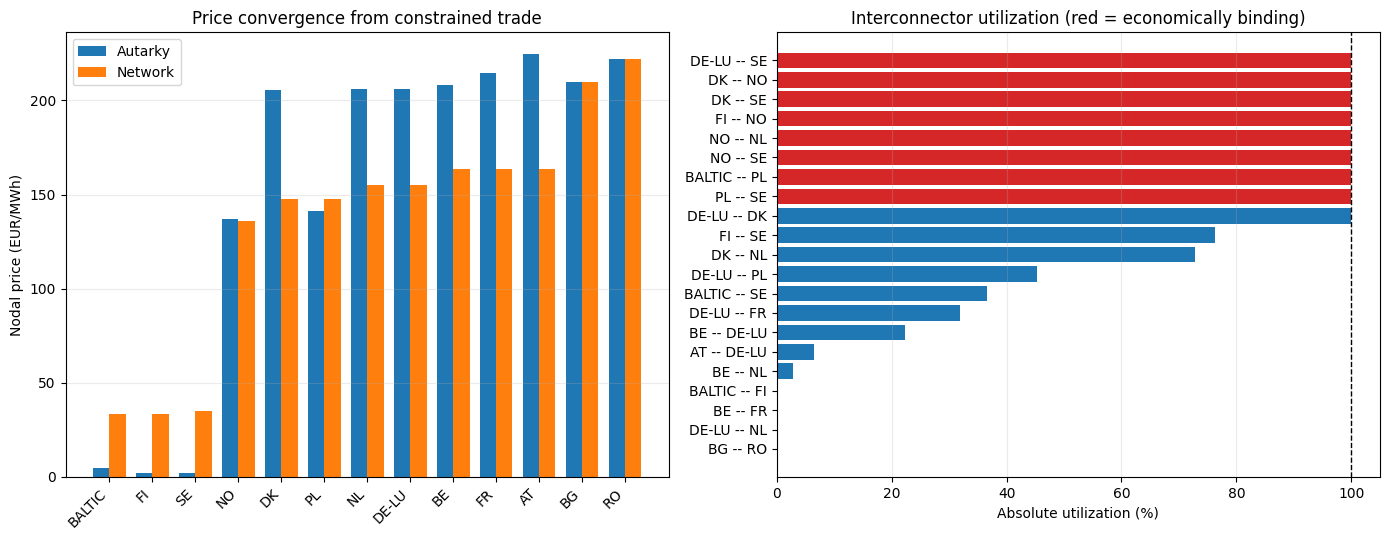

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

price_plot = node_comparison.sort_values("network_price")
x = np.arange(len(price_plot))
width = 0.38
axes[0].bar(x - width / 2, price_plot["autarky_price"], width, label="Autarky")
axes[0].bar(x + width / 2, price_plot["network_price"], width, label="Network")
axes[0].set_xticks(x, price_plot["market"], rotation=45, ha="right")
axes[0].set_ylabel("Nodal price (EUR/MWh)")
axes[0].set_title("Price convergence from constrained trade")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

utilization_plot = flow_display.sort_values("utilization_pct", ascending=True)
colors = np.where(utilization_plot["economically_binding"], "tab:red", "tab:blue")
axes[1].barh(
    utilization_plot["configured_link"],
    utilization_plot["utilization_pct"],
    color=colors,
)
axes[1].axvline(100, color="black", linewidth=1, linestyle="--")
axes[1].set_xlabel("Absolute utilization (%)")
axes[1].set_title("Interconnector utilization (red = economically binding)")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()

## 7. Numerical checks and interpretation

- `balance_residual_mw` should be essentially zero at every node. Sending flow is charged to the exporting market; only the retained fraction is credited to the receiving market.
- `at_limit` indicates flow equal to the directional capacity limit.
- Since direction choices make the main problem a MILP, nodal-price and marginal-capacity diagnostics come from a second LP with the optimal edge directions fixed. These are local diagnostics conditional on those directions.
- `marginal_value_of_more_capacity` is based on the fixed-direction LP reduced cost at an active capacity bound.
- Published-price comparisons are diagnostic only. The model omits loop flows, reserves, nonconvex bids, unit commitment, and other market rules.

In [29]:
diagnostics = pd.Series(
    {
        "max_abs_balance_residual_mw": network["nodes"]["balance_residual_mw"].abs().max(),
        "system_net_export_mw": network["nodes"]["net_export_mw"].sum(),
        "total_transmission_loss_mw": (network["flows"]["flow_mw"] - network["flows"]["received_mw"]).sum(),
        "interconnectors_at_limit": int(network["flows"]["at_limit"].sum()),
        "economically_binding_interconnectors": int(
            network["flows"]["economically_binding"].sum()
        ),
        "welfare_gain_eur_per_h": network["welfare"] - autarky["welfare"],
        "welfare_gain_for_15min_eur": 0.25 * (network["welfare"] - autarky["welfare"]),
    },
    name="value",
)
display(diagnostics.to_frame())

assert diagnostics["max_abs_balance_residual_mw"] <= 1e-5
assert np.isclose(
    diagnostics["system_net_export_mw"],
    diagnostics["total_transmission_loss_mw"],
    atol=1e-5,
)
assert network["welfare"] >= autarky["welfare"] - 1e-4
print("All numerical checks passed.")

,value
max_abs_balance_residual_mw,0.000
system_net_export_mw,455.262
total_transmission_loss_mw,455.262
interconnectors_at_limit,9.000
economically_binding_interconnectors,8.000
welfare_gain_eur_per_h,"537,635.164"
welfare_gain_for_15min_eur,"134,408.791"


All numerical checks passed.


## 8. Optional multi-period sensitivity

The same lossy market-clearing model can be run on several of the 96 delivery periods without extrapolating any curve. Set the switch below to `True` to compare representative overnight, morning, afternoon, and evening snapshots.

For a full-day welfare total, solve all 96 periods and multiply each EUR/hour objective by 0.25 hours before summing.

In [30]:
RUN_MULTI_PERIOD_SENSITIVITY = False
REPRESENTATIVE_PERIODS = [0, 28, 52, 76]


def run_period_sensitivity(markets, period_indices, interconnectors):
    rows = []
    for period_index in period_indices:
        one_period = prepare_period(markets, period_index)
        autarky_result = solve_market(
            one_period,
            AUTARKY_LINKS,
            model_name=f"autarky_period_{period_index}",
        )
        network_result = solve_market(
            one_period,
            interconnectors,
            model_name=f"network_period_{period_index}",
        )
        rows.append(
            {
                "period_index": period_index,
                "delivery_start": network_result["delivery_start"],
                "delivery_end": network_result["delivery_end"],
                "autarky_welfare_eur_per_h": autarky_result["welfare"],
                "network_welfare_eur_per_h": network_result["welfare"],
                "gain_for_15min_eur": 0.25 * (
                    network_result["welfare"] - autarky_result["welfare"]
                ),
                "economically_binding_links": int(
                    network_result["flows"]["economically_binding"].sum()
                ),
            }
        )
    return pd.DataFrame(rows)


if RUN_MULTI_PERIOD_SENSITIVITY:
    sensitivity_results = run_period_sensitivity(
        markets,
        REPRESENTATIVE_PERIODS,
        INTERCONNECTORS,
    )
    display(sensitivity_results)

## Suggested next extensions

1. Replace illustrative starting-link and candidate-link capacities with sourced, date-consistent transmission data.
2. Validate the capital-city coordinates, distance approximation, cost coefficient, and units for both costs and budget.
3. Run lossy clearing and greedy expansion across all 96 periods, then aggregate quarter-hour welfare and identify repeatedly selected edges.
4. Test sensitivity to the edge-loss fraction, candidate-link capacity, and budget multiplier before interpreting the greedy ranking.
5. If physical grid behavior is central to the research question, replace the transport approximation with a DC power-flow formulation and assess whether more detailed loss modelling is warranted.

## 9. Greedy transmission expansion

Starting links are treated as pre-existing, so only newly added edges count against the budget. At each iteration the search solves the current network plus each affordable unconnected edge and selects the edge with the largest welfare gain. It stops when no affordable edge remains, the best gain is not above `MIN_SURPLUS_GAIN`, the budget is used, or the iteration cap is reached.

A new edge receives the median capacity of the scaled starting links. Its cost uses the root OOP `Constants.cost_to_create()` convention: `int(1.6 * distance_km)` from capital-city coordinates. Budget, capacities and coordinates are illustrative; verify them before interpreting results.

In [31]:
from itertools import combinations


def greedy_expand_network(
    period_data,
    initial_interconnectors,
    budget_multiplier=BUDGET_MULTIPLIER,
    max_iterations=MAX_GREEDY_ITERATIONS,
    min_surplus_gain=MIN_SURPLUS_GAIN,
):
    """Greedily add welfare-improving links while respecting an investment budget."""
    nodes = sorted(period_data)
    missing = set(nodes) - set(MARKET_COORDINATES)
    if missing:
        raise KeyError(f"Missing coordinates for markets: {sorted(missing)}")
    all_pairs = list(combinations(nodes, 2))
    costs = {pair: edge_creation_cost(*pair) for pair in all_pairs}
    budget = float(budget_multiplier * max(costs.values()))
    spent = 0.0
    current = initial_interconnectors.reset_index(drop=True).copy()

    initial_solution = solve_market(period_data, current, model_name="greedy_initial", diagnostics=False)
    initial_welfare = float(initial_solution["welfare"])
    initial_solution["model"].dispose()
    current_welfare = initial_welfare
    history = []

    for iteration in range(1, max_iterations + 1):
        connected = {
            tuple(sorted((row.from_market, row.to_market)))
            for row in current.itertuples(index=False)
        }
        candidates = []
        for pair in all_pairs:
            if pair in connected:
                continue
            cost = costs[pair]
            if spent + cost > budget:
                continue
            new_edge = pd.DataFrame([{
                "from_market": pair[0],
                "to_market": pair[1],
                "capacity_mw": CANDIDATE_EDGE_CAPACITY_MW,
                "creation_cost": cost,
            }])
            trial_network = pd.concat([current, new_edge], ignore_index=True)
            trial = solve_market(
                period_data,
                trial_network,
                model_name=f"greedy_{iteration}_{pair[0]}_{pair[1]}",
                diagnostics=False,
            )
            trial_welfare = float(trial["welfare"])
            trial["model"].dispose()
            candidates.append((trial_welfare - current_welfare, pair, cost, trial_network, trial_welfare))

        if not candidates:
            print("Greedy search stopped: no unconnected edge fits the remaining budget.")
            break
        gain, pair, cost, next_network, next_welfare = max(candidates, key=lambda item: item[0])
        if gain <= min_surplus_gain:
            print(
                f"Greedy search stopped: best gain {gain:,.4f} does not exceed "
                f"the {min_surplus_gain:,.4f} threshold."
            )
            break

        spent += cost
        current = next_network
        current_welfare = next_welfare
        history.append({
            "iteration": iteration,
            "edge": f"{pair[0]} -- {pair[1]}",
            "capacity_mw": CANDIDATE_EDGE_CAPACITY_MW,
            "creation_cost": cost,
            "welfare_gain_eur_per_h": gain,
            "network_welfare_eur_per_h": current_welfare,
            "budget_spent": spent,
            "budget_remaining": budget - spent,
        })
        print(
            f"Iteration {iteration}: added {pair[0]} -- {pair[1]}, "
            f"gain={gain:,.2f} EUR/h, cost={cost}, remaining budget={budget-spent:,.2f}"
        )
        if spent >= budget:
            print("Greedy search stopped: expansion budget reached.")
            break

    return {
        "interconnectors": current,
        "history": pd.DataFrame(history),
        "initial_welfare": initial_welfare,
        "final_welfare": current_welfare,
        "budget": budget,
        "spent": spent,
    }


greedy_result = greedy_expand_network(period_data, INTERCONNECTORS)
greedy_summary = pd.DataFrame([{
    "initial_edges": len(INTERCONNECTORS),
    "added_edges": len(greedy_result["history"]),
    "final_edges": len(greedy_result["interconnectors"]),
    "initial_welfare_eur_per_h": greedy_result["initial_welfare"],
    "final_welfare_eur_per_h": greedy_result["final_welfare"],
    "total_welfare_gain_eur_per_h": greedy_result["final_welfare"] - greedy_result["initial_welfare"],
    "budget": greedy_result["budget"],
    "spent": greedy_result["spent"],
    "remaining_budget": greedy_result["budget"] - greedy_result["spent"],
}])
display(greedy_summary)
display(greedy_result["history"])
display(greedy_result["interconnectors"])

Iteration 1: added FI -- FR, gain=87,089.40 EUR/h, cost=4145, remaining budget=37,305.00
Iteration 2: added BALTIC -- DE-LU, gain=11,431.91 EUR/h, cost=2093, remaining budget=35,212.00
Iteration 3: added NL -- SE, gain=6,988.08 EUR/h, cost=2208, remaining budget=33,004.00
Iteration 4: added FI -- RO, gain=4,206.43 EUR/h, cost=2805, remaining budget=30,199.00
Iteration 5: added BE -- SE, gain=2,714.62 EUR/h, cost=2429, remaining budget=27,770.00
Iteration 6: added DE-LU -- FI, gain=3,476.50 EUR/h, cost=2034, remaining budget=25,736.00
Iteration 7: added FR -- SE, gain=3,187.36 EUR/h, cost=2868, remaining budget=22,868.00
Iteration 8: added AT -- FI, gain=1,889.99 EUR/h, cost=2406, remaining budget=20,462.00
Iteration 9: added BG -- FI, gain=241.34 EUR/h, cost=3103, remaining budget=17,359.00
Greedy search stopped: best gain 0.0000 does not exceed the 0.5000 threshold.


,initial_edges,added_edges,final_edges,initial_welfare_eur_per_h,final_welfare_eur_per_h,total_welfare_gain_eur_per_h,budget,spent,remaining_budget
0,21,9,30,"456,588,400.218","456,709,625.867","121,225.649","41,450.000","24,091.000","17,359.000"


,iteration,edge,capacity_mw,creation_cost,welfare_gain_eur_per_h,network_welfare_eur_per_h,budget_spent,budget_remaining
0,1,FI -- FR,"1,000.000",4145,"87,089.404","456,675,489.621","4,145.000","37,305.000"
1,2,BALTIC -- DE-LU,"1,000.000",2093,"11,431.911","456,686,921.533","6,238.000","35,212.000"
2,3,NL -- SE,"1,000.000",2208,"6,988.083","456,693,909.616","8,446.000","33,004.000"
3,4,FI -- RO,"1,000.000",2805,"4,206.431","456,698,116.047","11,251.000","30,199.000"
4,5,BE -- SE,"1,000.000",2429,"2,714.621","456,700,830.668","13,680.000","27,770.000"
5,6,DE-LU -- FI,"1,000.000",2034,"3,476.503","456,704,307.171","15,714.000","25,736.000"
6,7,FR -- SE,"1,000.000",2868,"3,187.365","456,707,494.535","18,582.000","22,868.000"
7,8,AT -- FI,"1,000.000",2406,"1,889.995","456,709,384.530","20,988.000","20,462.000"
8,9,BG -- FI,"1,000.000",3103,241.336,"456,709,625.867","24,091.000","17,359.000"


,from_market,to_market,capacity_mw,creation_cost
0,AT,DE-LU,"2,000.000",885
1,BE,DE-LU,"1,000.000",1384
2,BE,FR,"1,750.000",477
3,BE,NL,"1,200.000",283
4,DE-LU,FR,"2,000.000",1889
5,DE-LU,NL,"2,500.000",1329
6,DE-LU,PL,"1,250.000",1087
7,DE-LU,DK,"1,250.000",574
8,DE-LU,SE,300.000,1373
9,DK,NL,350.000,1335
